# Chiba sinks vs. observed flood mask

Compares the `chiba_sinks` depression-depth tiles (DEM sink/fill analysis) against a SAR-derived
flood mask, to see how well the sinks layer predicts where flooding actually occurred.

Everything here runs at each dataset's own **native resolution — no resampling anywhere**. An earlier
version of this notebook resampled the sink layer down onto the flood mask's coarser grid, but that
turned out to badly inflate the sink footprint: with sink tiles at ~1.11m and the flood mask at ~12m,
each output pixel aggregated ~94 native sink pixels via `Resampling.max`, so a real ~21-37% native sink
density got inflated to ~90%+ coverage after resampling — making the sinks layer look far more
permissive than it actually is. A full vector-polygon overlay was also tried and rejected: even a small
test area produced millions of individual polygons before the union step, risking memory exhaustion.

The approach that stuck: since all 49 sink tiles sit on one common, perfectly pixel-aligned native
grid, they can be mosaicked directly by placing each tile's raw array at its exact integer pixel
offset — no interpolation. The flood mask is never resampled either — for every native sink pixel, its
coordinates are computed directly and used to look up the corresponding flood-mask value via plain
array indexing (vectorized numpy, not a loop).

Pipeline:
- Inventory the 49 sink tiles and their combined extent.
- Pick a flood mask (`FLOOD_MASK_NATIVE`, swappable between a scoped test area and the full-Chiba event) and find which sink tiles overlap it.
- Compute the confusion matrix and depth-threshold sweep **per-tile** (bounded memory, works at any scale).
- If the combined native grid is small enough, also build one mosaicked array and: write a classification GeoTIFF, render both preview styles, export the missed/detected-vs-missed masks, compare TP vs. FN patch-size distributions, and zoom into the single biggest missed patch (with a full-Chiba locator map).

In [33]:
import glob
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.transform import from_origin
from rasterio.features import rasterize
from rasterio.windows import Window
from rasterio.enums import Resampling
from shapely.geometry import box
from scipy import ndimage
from scipy.ndimage import binary_dilation
from mpl_toolkits.axes_grid1.inset_locator import mark_inset
import matplotlib.pyplot as plt

SINK_DIR = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\chiba_sinks"
#FLOOD_MASK_NATIVE = r"C:\Users\Pedro\Documents\PSS\data\export_flood_cogs\export_flood_cogs\flood_mask_20260801_20260813.tif"
#FLOOD_MASK_NATIVE = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\oamishirasato_flood_mask.tif"
FLOOD_MASK_NATIVE = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\floods_chiba_final_mask.tif"
ADMIN = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\chiba_admin.geoparquet"
OUT_DIR = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\flood_sink_comparison"

SINK_NODATA = -9999.0

## Recortar la máscara de todo Chiba a la zona de Oamishirasato

`flood_mask_20260801_20260813.tif` cubre toda la prefectura, así que si se usara tal cual como
`FLOOD_MASK_NATIVE`, `native_overlap_tiles` pasaría a incluir los 49 tiles de sink (cualquier tile
overlapea con una máscara que cubre toda Chiba). Para comparar solo contra los mismos 7 tiles que usa
`oamishirasato_flood_mask.tif`, se recorta esa máscara completa a los bounds exactos de la máscara de
Oamishirasato (misma resolución nativa, sin resamplear — solo una ventana) y se guarda como un nuevo
GeoTIFF. La celda siguiente reasigna `FLOOD_MASK_NATIVE` para que apunte a este recorte, así el resto
del notebook (sin tocar la celda de configuración de arriba) ya opera solo sobre esos 7 tiles.

In [27]:
OAMISHIRASATO_REFERENCE_MASK = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\oamishirasato_flood_mask.tif"
FLOOD_MASK_FULL_CHIBA = r"C:\Users\Pedro\Documents\PSS\data\export_flood_cogs\export_flood_cogs\flood_mask_20260801_20260813.tif"
FLOOD_MASK_OAMISHIRASATO_CROP = OUT_DIR + r"\flood_mask_20260801_20260813_oamishirasato.tif"

with rasterio.open(OAMISHIRASATO_REFERENCE_MASK) as ref:
    crop_bounds = ref.bounds
    crop_crs = ref.crs

with rasterio.open(FLOOD_MASK_FULL_CHIBA) as src:
    assert src.crs == crop_crs, f"CRS mismatch: {src.crs} vs {crop_crs}"
    # Computed by hand (not rasterio.windows.from_bounds, which goes through
    # rasterio.transform.rowcol -- that call crashes the interpreter outright in this
    # environment, no Python exception at all, just a native access violation). This is
    # the same plain affine math the per-tile cells elsewhere in this notebook already use.
    t = src.transform
    left, bottom, right, top = crop_bounds
    col_off = int(round((left - t.c) / t.a))
    row_off = int(round((top - t.f) / t.e))
    col_end = int(round((right - t.c) / t.a))
    row_end = int(round((bottom - t.f) / t.e))
    crop_window = Window(col_off, row_off, col_end - col_off, row_end - row_off)
    crop_data = src.read(1, window=crop_window)
    crop_transform = src.window_transform(crop_window)
    crop_profile = src.profile.copy()

crop_profile.update(height=crop_data.shape[0], width=crop_data.shape[1], transform=crop_transform)

with rasterio.open(FLOOD_MASK_OAMISHIRASATO_CROP, "w", **crop_profile) as dst:
    dst.write(crop_data, 1)

print(f"recorte: {crop_data.shape[1]} x {crop_data.shape[0]} px")
print(f"fracción inundada en el recorte: {(crop_data > 0).mean()*100:.2f}%")
print(f"escrito en: {FLOOD_MASK_OAMISHIRASATO_CROP}")

FLOOD_MASK_NATIVE = FLOOD_MASK_OAMISHIRASATO_CROP
print(f"\nFLOOD_MASK_NATIVE ahora apunta al recorte (en vez del archivo de la celda de arriba)")

recorte: 3814 x 1954 px
fracción inundada en el recorte: 3.03%
escrito en: C:\Users\Pedro\Documents\PSS\data\chiba info all\flood_sink_comparison\flood_mask_20260801_20260813_oamishirasato.tif

FLOOD_MASK_NATIVE ahora apunta al recorte (en vez del archivo de la celda de arriba)


## Inventory sink tiles and combined extent

In [34]:
tiles = sorted(glob.glob(SINK_DIR + r"\*_sink.tif"))
print(f"found {len(tiles)} sink tiles")

minx = miny = 1e18
maxx = maxy = -1e18
tile_bounds = []
for f in tiles:
    with rasterio.open(f) as ds:
        b = ds.bounds
        tile_bounds.append((f, b))
        minx = min(minx, b.left); maxx = max(maxx, b.right)
        miny = min(miny, b.bottom); maxy = max(maxy, b.top)

print("combined sink bounds:", minx, miny, maxx, maxy)

found 49 sink tiles
combined sink bounds: 139.75 34.89166666800001 140.8875 35.75


## Map each sink tile to its source terrain tile

`chiba_tifs/tifs` is the source DEM the sink layer was derived from — same 49 mesh-code tiles,
pixel-identical footprint to the matching sink tile. The nodata pixels in these DEMs are NaN (and, in
some tiles, literal -9999 too) — not 0, which is a legitimate low-lying elevation. NaN prevalence
varies hugely by tile: from ~0% up to 97% of a tile in the worst cases. Wherever the terrain has no
real value, we have no basis for a sink determination there either, so those pixels get excluded from
every comparison below rather than silently counted as "no sink" (which would otherwise conflate
"sink analysis found nothing" with "we have no data at all").

In [35]:
import re

TERRAIN_DIR = r"C:\Users\Pedro\Documents\PSS\data\chiba info all\chiba_tifs\tifs"

terrain_by_code = {}
for tf in glob.glob(TERRAIN_DIR + r"\*.tif"):
    m = re.search(r"FG-GML-(\d{6})-", tf)
    if m:
        terrain_by_code[m.group(1)] = tf
print(f"found {len(terrain_by_code)} terrain tiles")

def terrain_path_for(sink_path):
    code = re.search(r"(\d{6})_sink", sink_path).group(1)
    return terrain_by_code[code]

_terrain_valid_cache = {}

def terrain_valid_mask(sink_path):
    """True where the source terrain has a real value.

    The actual nodata pixels are NaN (confirmed: prevalence ranges from ~0% up to 97% across the
    49 tiles), not 0 — 0 is a legitimate low-lying elevation. Several tiles also carry literal
    -9999 values on top of the NaN ones, so both are excluded. This is what QGIS is showing as
    "No Data" for these tiles. Cached per tile since the threshold sweep calls this repeatedly.
    """
    if sink_path not in _terrain_valid_cache:
        tpath = terrain_path_for(sink_path)
        with rasterio.open(tpath) as tds:
            t_arr = tds.read(1)
            t_nodata = tds.nodata
        valid = np.isfinite(t_arr)
        if t_nodata is not None:
            valid &= (t_arr != t_nodata)
        _terrain_valid_cache[sink_path] = valid
    return _terrain_valid_cache[sink_path]

found 49 terrain tiles


## Pick a flood mask and find overlapping sink tiles

In [36]:
with rasterio.open(FLOOD_MASK_NATIVE) as fds:
    native_flood_bounds = fds.bounds
    native_flood_transform = fds.transform
    native_flood_crs = fds.crs
    native_fH, native_fW = fds.height, fds.width
    native_flood_arr = fds.read(1)

native_flood_bbox = box(native_flood_bounds.left, native_flood_bounds.bottom, native_flood_bounds.right, native_flood_bounds.top)
native_overlap_tiles = [(f, b) for f, b in tile_bounds if box(b.left, b.bottom, b.right, b.top).intersects(native_flood_bbox)]
print(f"{len(native_overlap_tiles)} of {len(tile_bounds)} sink tiles overlap this flood mask's extent")

gdf = gpd.read_parquet(ADMIN)
gdf_nat = gdf if gdf.crs == native_flood_crs else gdf.to_crs(native_flood_crs)

7 of 49 sink tiles overlap this flood mask's extent


## Confusion matrix + threshold sweep (per-tile)

In [37]:
nTP = nFP = nFN = nTN = 0
n_lat_c = (native_flood_bounds.bottom + native_flood_bounds.top) / 2
n_deg_to_m_lat = 111320.0
n_deg_to_m_lon = 111320.0 * np.cos(np.radians(n_lat_c))

for f, b in native_overlap_tiles:
    with rasterio.open(f) as tds:
        arr = tds.read(1)
        t = tds.transform
    h, w = arr.shape

    cols = np.arange(w)
    rows = np.arange(h)
    lon = t.c + (cols + 0.5) * t.a
    lat = t.f + (rows + 0.5) * t.e

    fcol = np.floor((lon - native_flood_transform.c) / native_flood_transform.a).astype(np.int32)
    frow = np.floor((lat - native_flood_transform.f) / native_flood_transform.e).astype(np.int32)
    in_col = (fcol >= 0) & (fcol < native_fW)
    in_row = (frow >= 0) & (frow < native_fH)
    fcol_c = np.clip(fcol, 0, native_fW - 1)
    frow_c = np.clip(frow, 0, native_fH - 1)

    flood_lookup = native_flood_arr[frow_c[:, None], fcol_c[None, :]]
    in_range = in_row[:, None] & in_col[None, :]
    flood_present = (flood_lookup > 0) & in_range

    admin_mask = rasterize(
        [(g, 1) for g in gdf_nat.geometry.values],
        out_shape=(h, w), transform=t, fill=0, dtype=np.uint8,
    ).astype(bool)
    sink_present = arr != SINK_NODATA
    valid = admin_mask & in_range & terrain_valid_mask(f)

    nTP += int(np.count_nonzero(sink_present & flood_present & valid))
    nFP += int(np.count_nonzero(sink_present & ~flood_present & valid))
    nFN += int(np.count_nonzero(~sink_present & flood_present & valid))
    nTN += int(np.count_nonzero(~sink_present & ~flood_present & valid))
    print(f"{f.split(chr(92))[-1]}: done")

print(f"\nprocessed {len(native_overlap_tiles)} tiles")

534002_sink.tif: done
534003_sink.tif: done
534012_sink.tif: done
534013_sink.tif: done
534022_sink.tif: done
534023_sink.tif: done
534024_sink.tif: done

processed 7 tiles


In [38]:
n_total = nTP + nFP + nFN + nTN
n_precision = nTP / (nTP + nFP) if (nTP + nFP) else float("nan")
n_recall = nTP / (nTP + nFN) if (nTP + nFN) else float("nan")
n_iou = nTP / (nTP + nFP + nFN) if (nTP + nFP + nFN) else float("nan")
n_base_rate = (nTP + nFN) / n_total if n_total else float("nan")

print("=== CONFUSION MATRIX ===")
print(f"TP: {nTP:,}   FP: {nFP:,}   FN: {nFN:,}   TN: {nTN:,}   total: {n_total:,}")
print(f"precision: {n_precision*100:.2f}%  recall: {n_recall*100:.2f}%  IoU: {n_iou:.4f}")
print(f"base flood rate: {n_base_rate*100:.3f}%  lift: {n_precision/n_base_rate:.2f}x")

print("\n=== THRESHOLD SWEEP (per-tile accumulation) ===")
print(f"{'thresh(m)':>10} | {'precision':>10} | {'recall':>10} | {'IoU':>8}")
for thresh in [0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]:
    tp = fp = fn = 0
    for f, b in native_overlap_tiles:
        with rasterio.open(f) as tds:
            arr = tds.read(1)
            t = tds.transform
        h, w = arr.shape
        cols = np.arange(w); rows = np.arange(h)
        lon = t.c + (cols + 0.5) * t.a
        lat = t.f + (rows + 0.5) * t.e
        fcol = np.floor((lon - native_flood_transform.c) / native_flood_transform.a).astype(np.int32)
        frow = np.floor((lat - native_flood_transform.f) / native_flood_transform.e).astype(np.int32)
        in_col = (fcol >= 0) & (fcol < native_fW)
        in_row = (frow >= 0) & (frow < native_fH)
        fcol_c = np.clip(fcol, 0, native_fW - 1)
        frow_c = np.clip(frow, 0, native_fH - 1)
        in_range = in_row[:, None] & in_col[None, :]
        flood_present = (native_flood_arr[frow_c[:, None], fcol_c[None, :]] > 0) & in_range
        admin_mask = rasterize([(g, 1) for g in gdf_nat.geometry.values], out_shape=(h, w), transform=t, fill=0, dtype=np.uint8).astype(bool)
        valid = admin_mask & in_range & terrain_valid_mask(f)
        pred = (arr != SINK_NODATA) & (arr >= thresh) & valid
        tp += int(np.count_nonzero(pred & flood_present))
        fp += int(np.count_nonzero(pred & ~flood_present))
        fn += int(np.count_nonzero(~pred & flood_present & valid))
    prec = tp / (tp + fp) if (tp + fp) else float("nan")
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    iout = tp / (tp + fp + fn) if (tp + fp + fn) else float("nan")
    print(f"{thresh:>10.2f} | {prec*100:9.2f}% | {rec*100:9.2f}% | {iout:8.4f}")

=== CONFUSION MATRIX ===
TP: 2,048,013   FP: 111,306,874   FN: 482,690   TN: 162,995,679   total: 276,833,256
precision: 1.81%  recall: 80.93%  IoU: 0.0180
base flood rate: 0.914%  lift: 1.98x

=== THRESHOLD SWEEP (per-tile accumulation) ===
 thresh(m) |  precision |     recall |      IoU
      0.00 |      1.81% |     80.93% |   0.0180
      0.05 |      2.19% |     76.83% |   0.0218
      0.10 |      2.44% |     74.38% |   0.0242
      0.25 |      2.95% |     66.14% |   0.0291
      0.50 |      4.34% |     50.93% |   0.0416
      1.00 |      9.77% |     28.76% |   0.0787
      2.00 |      9.68% |      8.09% |   0.0461
      5.00 |      6.63% |      0.88% |   0.0078


## Detected-vs-missed flood mask (green/red), streamed to disk — works at any scale

Unlike the classification raster below, this only needs a per-pixel decision (is this flooded pixel
detected or missed?), which needs no context from neighboring pixels — so it never requires a combined
array in memory at all. Each tile's block is computed and written directly into its exact window of an
output GeoTIFF on disk, one tile at a time. This works identically whether `FLOOD_MASK_NATIVE` is
scoped to a small test area or the full-Chiba event.

In [39]:
sminx = min(b.left for _, b in native_overlap_tiles)
smaxx = max(b.right for _, b in native_overlap_tiles)
sminy = min(b.bottom for _, b in native_overlap_tiles)
smaxy = max(b.top for _, b in native_overlap_tiles)
with rasterio.open(native_overlap_tiles[0][0]) as ds:
    stream_res = ds.res
    stream_crs = ds.crs

stream_W = round((smaxx - sminx) / stream_res[0])
stream_H = round((smaxy - sminy) / stream_res[1])
stream_transform = from_origin(sminx, smaxy, stream_res[0], stream_res[1])
print(f"output grid: {stream_H:,} x {stream_W:,} = {stream_H*stream_W:,} px (written directly to disk, tile by tile)")

stream_profile = {
    "driver": "GTiff", "height": stream_H, "width": stream_W, "count": 1, "dtype": "uint8",
    "crs": stream_crs, "transform": stream_transform, "nodata": 0, "compress": "deflate",
    "tiled": True, "blockxsize": 512, "blockysize": 512,
}
stream_out_path = OUT_DIR + r"\full_flood_detected_vs_missed.tif"

total_detected = total_missed = 0
with rasterio.open(stream_out_path, "w", **stream_profile) as dst:
    dst.write_colormap(1, {0: (0, 0, 0, 0), 1: (34, 139, 34, 255), 2: (220, 20, 60, 255)})
    for f, b in native_overlap_tiles:
        with rasterio.open(f) as ds:
            arr = ds.read(1)
            t = ds.transform
        h, w = arr.shape

        cols = np.arange(w); rows = np.arange(h)
        lon = t.c + (cols + 0.5) * t.a
        lat = t.f + (rows + 0.5) * t.e
        fcol = np.floor((lon - native_flood_transform.c) / native_flood_transform.a).astype(np.int32)
        frow = np.floor((lat - native_flood_transform.f) / native_flood_transform.e).astype(np.int32)
        in_col = (fcol >= 0) & (fcol < native_fW)
        in_row = (frow >= 0) & (frow < native_fH)
        fcol_c = np.clip(fcol, 0, native_fW - 1)
        frow_c = np.clip(frow, 0, native_fH - 1)
        in_range = in_row[:, None] & in_col[None, :]
        flood_present = (native_flood_arr[frow_c[:, None], fcol_c[None, :]] > 0) & in_range

        admin_mask = rasterize(
            [(g, 1) for g in gdf_nat.geometry.values],
            out_shape=(h, w), transform=t, fill=0, dtype=np.uint8,
        ).astype(bool)
        sink_present = arr != SINK_NODATA
        flooded_valid = admin_mask & in_range & terrain_valid_mask(f) & flood_present

        status = np.zeros((h, w), dtype=np.uint8)
        status[flooded_valid & sink_present] = 1    # detected
        status[flooded_valid & ~sink_present] = 2   # missed

        row_off = round((smaxy - b.top) / stream_res[1])
        col_off = round((b.left - sminx) / stream_res[0])
        dst.write(status, 1, window=Window(col_off, row_off, w, h))

        d, m = int((status == 1).sum()), int((status == 2).sum())
        total_detected += d; total_missed += m
        print(f"{f.split(chr(92))[-1]}: wrote block  (detected {d:,}, missed {m:,})")

print(f"\nwrote {stream_out_path}")
print(f"total detected: {total_detected:,}   total missed: {total_missed:,}   "
      f"recall: {100*total_detected/(total_detected+total_missed):.2f}%")

output grid: 22,500 x 23,625 = 531,562,500 px (written directly to disk, tile by tile)
534002_sink.tif: wrote block  (detected 98,025, missed 88,005)
534003_sink.tif: wrote block  (detected 5,321, missed 11,851)
534012_sink.tif: wrote block  (detected 887,659, missed 145,498)
534013_sink.tif: wrote block  (detected 32,396, missed 18,310)
534022_sink.tif: wrote block  (detected 586,207, missed 145,600)
534023_sink.tif: wrote block  (detected 438,405, missed 73,426)
534024_sink.tif: wrote block  (detected 0, missed 0)

wrote C:\Users\Pedro\Documents\PSS\data\chiba info all\flood_sink_comparison\full_flood_detected_vs_missed.tif
total detected: 2,048,013   total missed: 482,690   recall: 80.93%


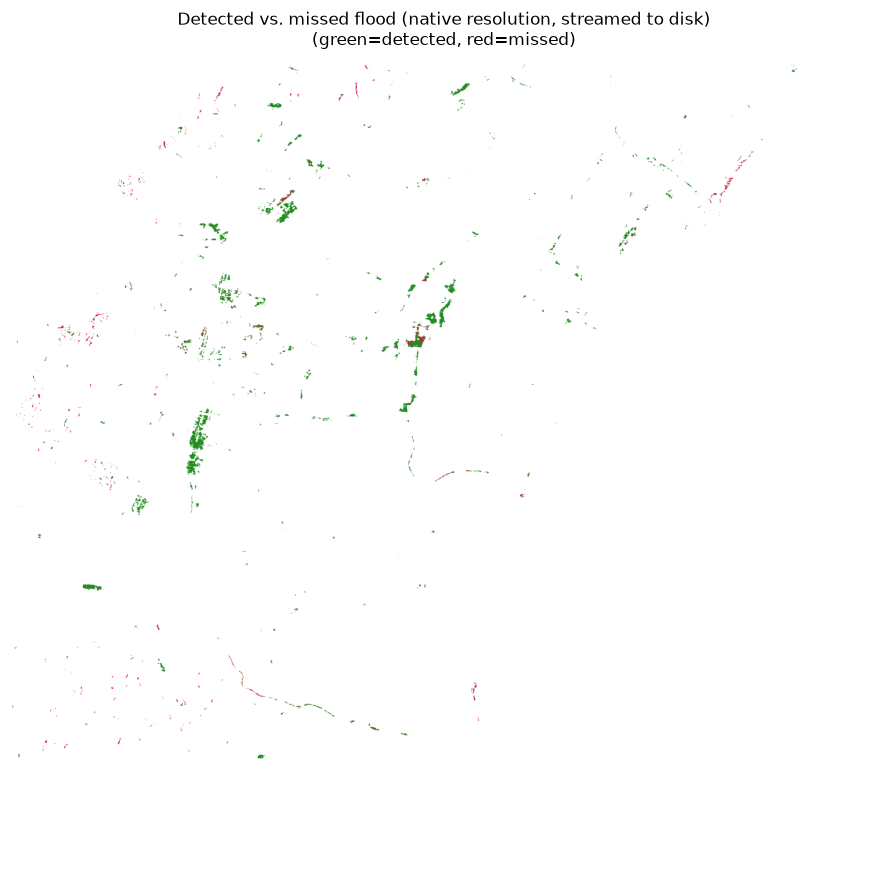

In [40]:
with rasterio.open(stream_out_path) as ds:
    factor = max(1, ds.width // 3000)
    preview = ds.read(1, out_shape=(ds.height // factor, ds.width // factor), resampling=Resampling.nearest)

status_colors = {0: (1, 1, 1), 1: (0.13, 0.55, 0.13), 2: (0.86, 0.08, 0.24)}
rgb_stream = np.zeros((*preview.shape, 3))
for k, c in status_colors.items():
    rgb_stream[preview == k] = c

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(rgb_stream)
ax.set_title("Detected vs. missed flood (native resolution, streamed to disk)\n(green=detected, red=missed)")
ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR + r"\full_flood_detected_vs_missed_preview.png", dpi=150)
plt.show()

### Classification raster, previews, and patch analysis — only if the combined grid is small enough

The confusion matrix and threshold sweep above are computed per-tile, so they scale to any flood mask
(Oamishirasato's 7 tiles or all 49 for the full-Chiba event) with bounded memory. The steps below
(classification raster, previews, connected-component patch analysis, biggest-miss zoom) need one
combined array in memory at once, which is only safe at a smaller scale — this cell checks the
combined grid size first and skips the rest of this section with an explanation if it's too large
(e.g. if `FLOOD_MASK_NATIVE` above is switched to the full-Chiba mask, all 49 tiles combine to ~7.9
billion native pixels, which is not memory-feasible for the patch-labeling step).

In [41]:
MAX_NATIVE_PIXELS_FOR_FULL_ANALYSIS = 2_000_000_000
# Don't raise this casually: the combined mosaic needs several full-size arrays at once
# (sink_depth_native alone is float32 = 4 bytes/px = ~31.6GB at the full-Chiba 7.9B-px scale,
# plus several boolean arrays on top of that) — it's not just one uint8 array's worth of RAM.

nminx = nminy = 1e18
nmaxx = nmaxy = -1e18
for f, b in native_overlap_tiles:
    nminx = min(nminx, b.left); nmaxx = max(nmaxx, b.right)
    nminy = min(nminy, b.bottom); nmaxy = max(nmaxy, b.top)

with rasterio.open(native_overlap_tiles[0][0]) as ds:
    native_res = ds.res
    native_crs = ds.crs

nW = round((nmaxx - nminx) / native_res[0])
nH = round((nmaxy - nminy) / native_res[1])
estimated_px = nH * nW
print(f"combined native grid would be {nH:,} x {nW:,} = {estimated_px:,} px")

RUN_FULL_NATIVE_MOSAIC = estimated_px <= MAX_NATIVE_PIXELS_FOR_FULL_ANALYSIS
if not RUN_FULL_NATIVE_MOSAIC:
    print(f"\nSKIPPING classification raster / previews / patch analysis below: {estimated_px:,} px exceeds "
          f"the {MAX_NATIVE_PIXELS_FOR_FULL_ANALYSIS:,} px safety cap. This is expected if FLOOD_MASK_NATIVE "
          f"is set to the full-Chiba mask — the confusion matrix and threshold sweep above already ran in "
          f"full regardless, since those are computed per-tile. To run the rest, scope FLOOD_MASK_NATIVE "
          f"to a smaller area (like Oamishirasato) instead of raising this cap.")
else:
    native_transform = from_origin(nminx, nmaxy, native_res[0], native_res[1])
    sink_depth_native = np.full((nH, nW), np.nan, dtype=np.float32)
    # The 49 tiles don't necessarily tile their own combined bounding rectangle without gaps —
    # track which pixels actually come from a real tile file, separately from "tile says no sink
    # here" (SINK_NODATA). Without this, a gap pixel is indistinguishable from a real "no sink"
    # pixel, and a flood there gets wrongly counted as a miss (FN) instead of excluded outright.
    tile_coverage_native = np.zeros((nH, nW), dtype=bool)
    # Same idea, but for terrain validity: wherever the source DEM has no real value (0), we have
    # no basis for a sink determination there either, so exclude those pixels too.
    terrain_valid_native = np.zeros((nH, nW), dtype=bool)
    for f, b in native_overlap_tiles:
        with rasterio.open(f) as ds:
            arr = ds.read(1)
        row_off = round((nmaxy - b.top) / native_res[1])
        col_off = round((b.left - nminx) / native_res[0])
        h, w = arr.shape
        sub = sink_depth_native[row_off:row_off + h, col_off:col_off + w]
        sub[:] = np.where(arr == SINK_NODATA, np.nan, arr)
        tile_coverage_native[row_off:row_off + h, col_off:col_off + w] = True
        terrain_valid_native[row_off:row_off + h, col_off:col_off + w] = terrain_valid_mask(f)
    sink_present_native = ~np.isnan(sink_depth_native)
    n_gap_px = int((~tile_coverage_native).sum())
    print(f"native sink mosaic done: {int(sink_present_native.sum()):,} sink px, "
          f"{n_gap_px:,} px ({100*n_gap_px/estimated_px:.2f}%) are gaps outside real tile coverage")

    ncols = np.arange(nW); nrows = np.arange(nH)
    nlon = native_transform.c + (ncols + 0.5) * native_transform.a
    nlat = native_transform.f + (nrows + 0.5) * native_transform.e
    nfcol = np.floor((nlon - native_flood_transform.c) / native_flood_transform.a).astype(np.int32)
    nfrow = np.floor((nlat - native_flood_transform.f) / native_flood_transform.e).astype(np.int32)
    n_in_col = (nfcol >= 0) & (nfcol < native_fW)
    n_in_row = (nfrow >= 0) & (nfrow < native_fH)
    nfcol_c = np.clip(nfcol, 0, native_fW - 1)
    nfrow_c = np.clip(nfrow, 0, native_fH - 1)
    n_in_range = n_in_row[:, None] & n_in_col[None, :]
    flood_present_native = (native_flood_arr[nfrow_c[:, None], nfcol_c[None, :]] > 0) & n_in_range
    del nfcol, nfrow, nfcol_c, nfrow_c

    admin_mask_native = rasterize(
        [(g, 1) for g in gdf_nat.geometry.values],
        out_shape=(nH, nW), transform=native_transform, fill=0, dtype=np.uint8,
    ).astype(bool)
    # Restricted here, at the start, so every downstream cell (classification, patch analysis,
    # biggest-miss zoom) inherits the restriction automatically instead of needing its own fix.
    valid_area_native = admin_mask_native & n_in_range & tile_coverage_native & terrain_valid_native
    sink_present_native &= valid_area_native
    flood_present_native &= valid_area_native
    print(f"native admin mask done: {int(valid_area_native.sum()):,} valid px")

combined native grid would be 22,500 x 23,625 = 531,562,500 px
native sink mosaic done: 123,033,329 sink px, 134,156,250 px (25.24%) are gaps outside real tile coverage
native admin mask done: 276,833,253 valid px


wrote C:\Users\Pedro\Documents\PSS\data\chiba info all\flood_sink_comparison\oami_native_classification.tif


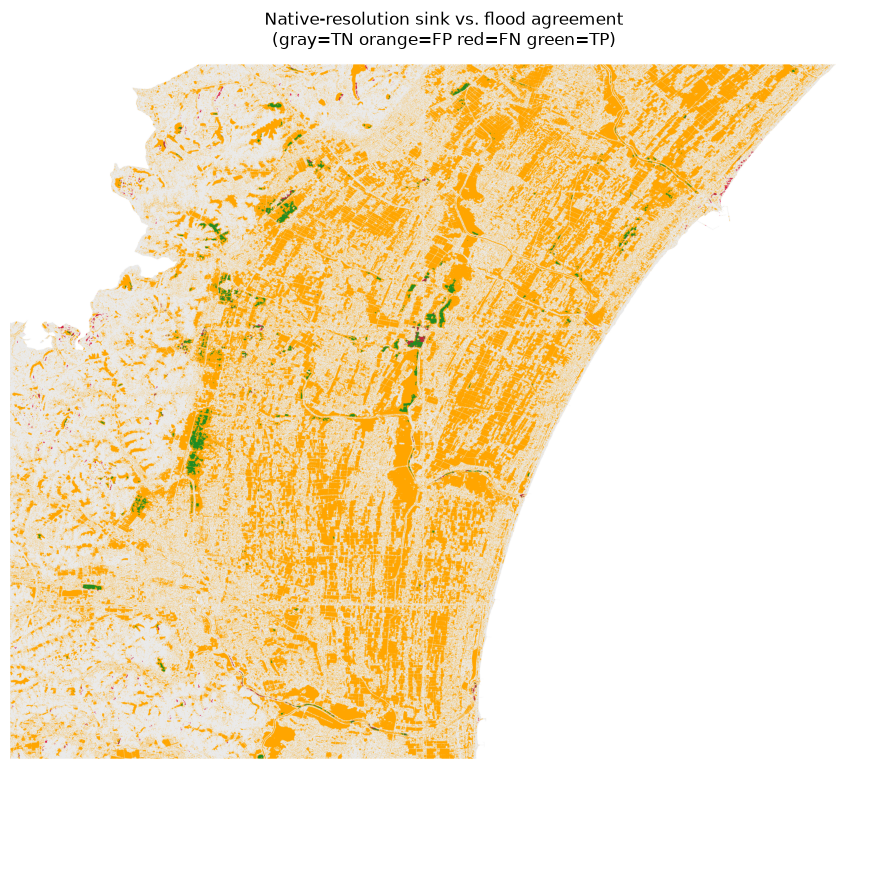

In [42]:
if RUN_FULL_NATIVE_MOSAIC:
    classified_native = np.zeros((nH, nW), dtype=np.uint8)

    # process in row-chunks so we never allocate a full-size temporary boolean array at once
    chunk_rows = 256
    for r0 in range(0, nH, chunk_rows):
        r1 = min(r0 + chunk_rows, nH)
        valid = valid_area_native[r0:r1]
        sink = sink_present_native[r0:r1]
        flood = flood_present_native[r0:r1]
        chunk = classified_native[r0:r1]
        chunk[valid & ~sink & ~flood] = 1
        chunk[valid & sink & ~flood] = 2
        chunk[valid & ~sink & flood] = 3
        chunk[valid & sink & flood] = 4

    native_profile = {
        "driver": "GTiff", "height": nH, "width": nW, "count": 1, "dtype": "uint8",
        "crs": native_crs, "transform": native_transform, "nodata": 0, "compress": "deflate",
    }
    native_class_path = OUT_DIR + r"\oami_native_classification.tif"
    with rasterio.open(native_class_path, "w", **native_profile) as dst:
        dst.write(classified_native, 1)
        dst.write_colormap(1, {
            0: (0, 0, 0, 0), 1: (240, 240, 240, 255), 2: (255, 165, 0, 255),
            3: (220, 20, 60, 255), 4: (34, 139, 34, 255),
        })
    print(f"wrote {native_class_path}")

    colors = {0: (1, 1, 1), 1: (0.92, 0.92, 0.92), 2: (1.0, 0.65, 0.0), 3: (0.86, 0.08, 0.24), 4: (0.13, 0.55, 0.13)}
    factor = 6
    small = classified_native[::factor, ::factor]
    rgb = np.zeros((*small.shape, 3))
    for k, c in colors.items():
        rgb[small == k] = c
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.imshow(rgb)
    ax.set_title("Native-resolution sink vs. flood agreement\n(gray=TN orange=FP red=FN green=TP)")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR + r"\oami_native_preview.png", dpi=150)
    plt.show()

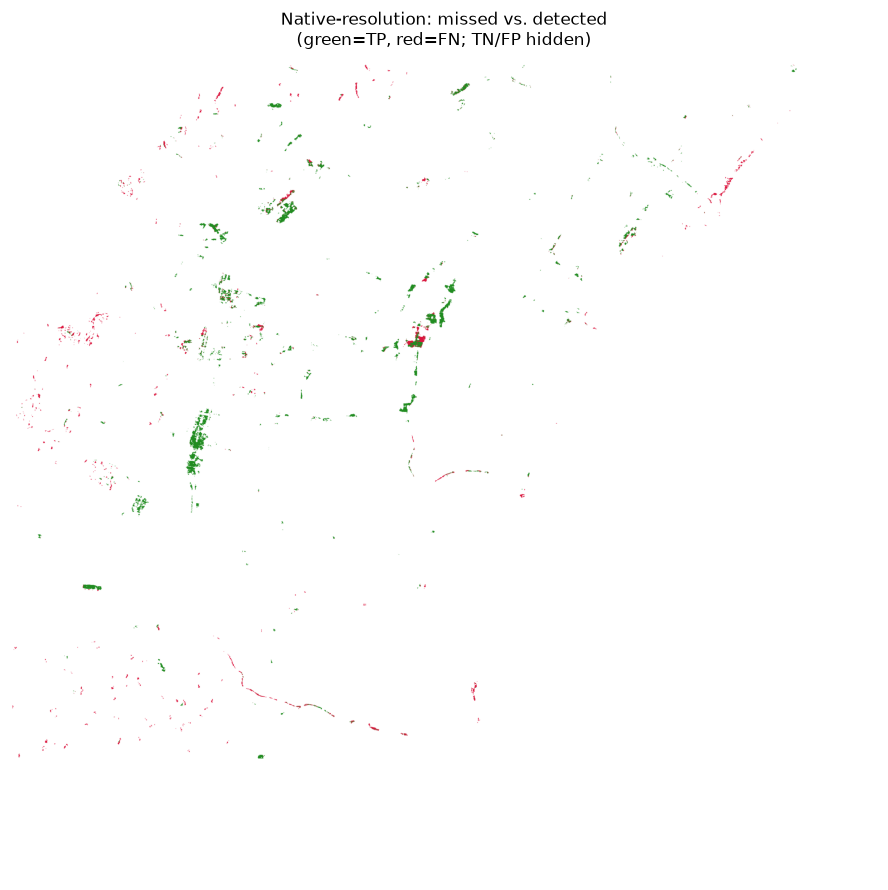

In [43]:
if RUN_FULL_NATIVE_MOSAIC:
    tp_small_native = classified_native[::4, ::4] == 4
    fn_dilated_native = binary_dilation(classified_native == 3, iterations=2)[::4, ::4]
    rgb_hl = np.ones((*tp_small_native.shape, 3))
    rgb_hl[tp_small_native] = (0.13, 0.55, 0.13)
    rgb_hl[fn_dilated_native] = (0.86, 0.08, 0.24)

    fig, ax = plt.subplots(figsize=(11, 9))
    ax.imshow(rgb_hl)
    ax.set_title("Native-resolution: missed vs. detected\n(green=TP, red=FN; TN/FP hidden)")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR + r"\oami_native_misses_highlighted.png", dpi=150)
    plt.show()

In [44]:
if RUN_FULL_NATIVE_MOSAIC:
    undetected_mask_native = (classified_native == 3).astype(np.uint8)
    with rasterio.open(OUT_DIR + r"\oami_native_undetected_flood_mask.tif", "w", **native_profile) as dst:
        dst.write(undetected_mask_native, 1)
        dst.write_colormap(1, {0: (0, 0, 0, 0), 1: (220, 20, 60, 255)})
    print(f"wrote oami_native_undetected_flood_mask.tif ({int(undetected_mask_native.sum()):,} px)")

    flood_status_native = np.zeros((nH, nW), dtype=np.uint8)
    flood_status_native[classified_native == 4] = 1
    flood_status_native[classified_native == 3] = 2
    with rasterio.open(OUT_DIR + r"\oami_native_flood_detected_vs_missed.tif", "w", **native_profile) as dst:
        dst.write(flood_status_native, 1)
        dst.write_colormap(1, {0: (0, 0, 0, 0), 1: (34, 139, 34, 255), 2: (220, 20, 60, 255)})
    print(f"wrote oami_native_flood_detected_vs_missed.tif  (detected {int((flood_status_native==1).sum()):,}, missed {int((flood_status_native==2).sum()):,})")

wrote oami_native_undetected_flood_mask.tif (482,689 px)
wrote oami_native_flood_detected_vs_missed.tif  (detected 2,048,013, missed 482,689)


In [45]:
if RUN_FULL_NATIVE_MOSAIC:
    n_px_w_m = abs(native_transform.a) * n_deg_to_m_lon
    n_px_h_m = abs(native_transform.e) * n_deg_to_m_lat

    native_results = {}
    for name, mask in [("DETECTED (TP)", classified_native == 4), ("MISSED (FN)", classified_native == 3)]:
        labeled, n = ndimage.label(mask, structure=np.ones((3, 3)))
        sizes = ndimage.sum(np.ones_like(labeled), labeled, index=np.arange(1, n + 1)).astype(int)
        native_results[name] = (labeled, sizes)
        print(f"=== {name} ===")
        print(f"  patches: {n:,}, largest {sizes.max():,} px ({sizes.max()*n_px_w_m*n_px_h_m:.1f} m2)")
        print(f"  median: {np.median(sizes):.1f} px, mean: {sizes.mean():.2f} px")

    ratio_native = native_results["DETECTED (TP)"][1].max() / native_results["MISSED (FN)"][1].max()
    print(f"\nlargest detected patch is {ratio_native:.2f}x bigger than the largest missed patch")

=== DETECTED (TP) ===
  patches: 10,452, largest 158,142 px (197028.8 m2)
  median: 3.0 px, mean: 195.94 px
=== MISSED (FN) ===
  patches: 7,571, largest 19,570 px (24382.2 m2)
  median: 1.0 px, mean: 63.75 px

largest detected patch is 8.08x bigger than the largest missed patch


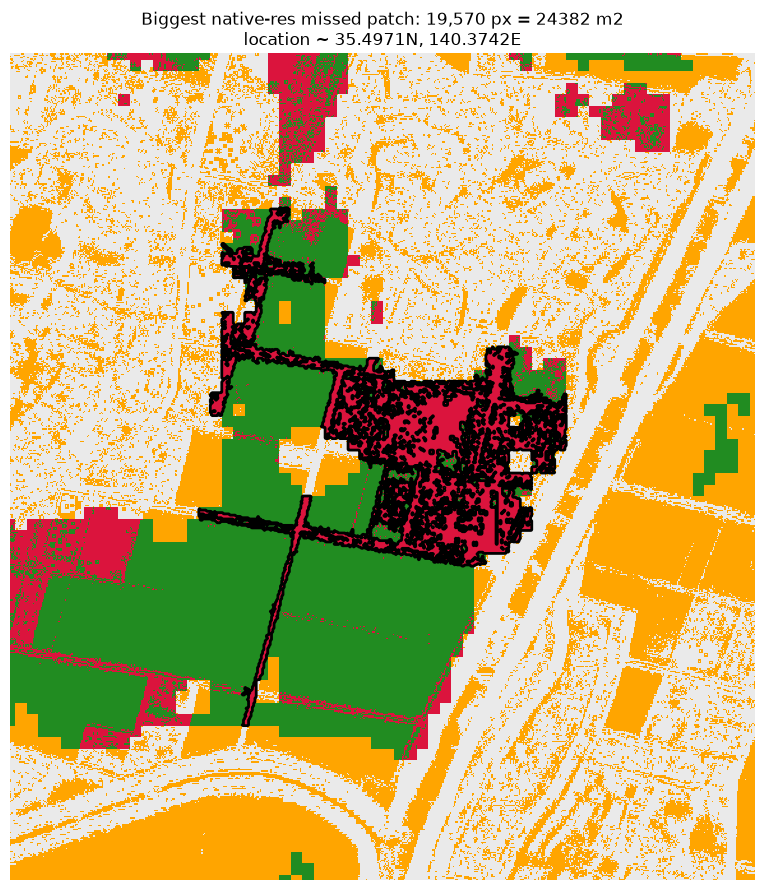

In [46]:
if RUN_FULL_NATIVE_MOSAIC:
    fn_labeled_native, fn_sizes_native = native_results["MISSED (FN)"]
    target_label_n = int(np.argmax(fn_sizes_native)) + 1
    target_size_n = fn_sizes_native[target_label_n - 1]

    objs_n = ndimage.find_objects(fn_labeled_native)
    sl = objs_n[target_label_n - 1]
    r0, r1, c0, c1 = sl[0].start, sl[0].stop, sl[1].start, sl[1].stop
    buf_r = int(150 / n_px_h_m); buf_c = int(150 / n_px_w_m)
    rr0, rr1 = max(0, r0 - buf_r), min(nH, r1 + buf_r)
    cc0, cc1 = max(0, c0 - buf_c), min(nW, c1 + buf_c)

    crop_n = classified_native[rr0:rr1, cc0:cc1]
    target_crop_n = (fn_labeled_native[rr0:rr1, cc0:cc1] == target_label_n)
    rgb_zoom_n = np.zeros((*crop_n.shape, 3))
    for k, c in colors.items():
        rgb_zoom_n[crop_n == k] = c

    left_n = native_transform.c + cc0 * native_transform.a
    right_n = native_transform.c + cc1 * native_transform.a
    top_n = native_transform.f + rr0 * native_transform.e
    bottom_n = native_transform.f + rr1 * native_transform.e
    cy_n, cx_n = ndimage.center_of_mass(fn_labeled_native == target_label_n)
    lon_n, lat_n = rasterio.transform.xy(native_transform, cy_n, cx_n)

    fig, ax = plt.subplots(figsize=(10, 9))
    ax.imshow(rgb_zoom_n, extent=(left_n, right_n, bottom_n, top_n), origin="upper", interpolation="nearest")
    ax.contour(target_crop_n.astype(float), levels=[0.5], colors="black", linewidths=2.0,
               extent=(left_n, right_n, bottom_n, top_n), origin="upper")
    ax.set_title(f"Biggest native-res missed patch: {target_size_n:,} px = {target_size_n*n_px_w_m*n_px_h_m:.0f} m2\n"
                 f"location ~ {lat_n:.4f}N, {lon_n:.4f}E")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR + r"\oami_native_biggest_missed_patch.png", dpi=170)
    plt.show()

## Same native-resolution patch, with the full Chiba bounding box as context

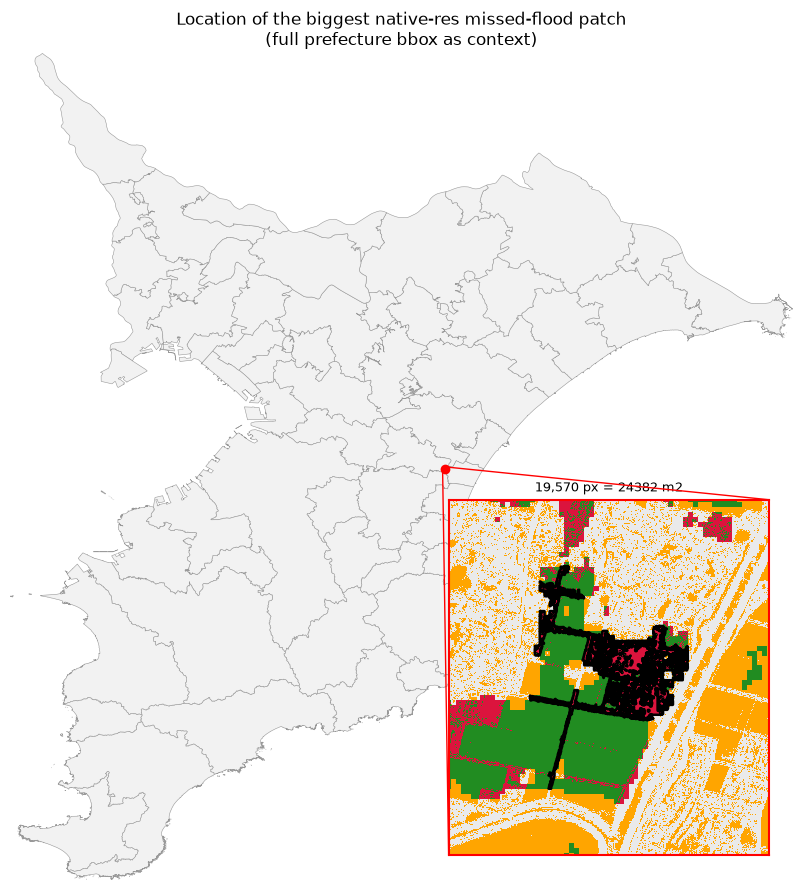

In [47]:
if RUN_FULL_NATIVE_MOSAIC:
    fig, ax_main = plt.subplots(figsize=(11, 9))
    gdf_nat.plot(ax=ax_main, color="#f2f2f2", edgecolor="0.6", linewidth=0.4, zorder=1)
    ax_main.plot(lon_n, lat_n, marker="o", color="red", markersize=6, zorder=5)
    ax_main.set_title("Location of the biggest native-res missed-flood patch\n(full prefecture bbox as context)")
    ax_main.set_xlim(*gdf_nat.total_bounds[[0, 2]])
    ax_main.set_ylim(*gdf_nat.total_bounds[[1, 3]])
    ax_main.set_aspect("equal")
    ax_main.axis("off")

    ax_inset = ax_main.inset_axes([0.55, 0.03, 0.43, 0.43])
    ax_inset.imshow(rgb_zoom_n, extent=(left_n, right_n, bottom_n, top_n), origin="upper", interpolation="nearest", zorder=2)
    ax_inset.contour(target_crop_n.astype(float), levels=[0.5], colors="black", linewidths=1.8,
                      extent=(left_n, right_n, bottom_n, top_n), origin="upper")
    ax_inset.set_xlim(left_n, right_n)
    ax_inset.set_ylim(bottom_n, top_n)
    ax_inset.set_xticks([]); ax_inset.set_yticks([])
    for spine in ax_inset.spines.values():
        spine.set_edgecolor("red"); spine.set_linewidth(1.5)
    ax_inset.set_title(f"{target_size_n:,} px = {target_size_n*n_px_w_m*n_px_h_m:.0f} m2", fontsize=9)

    mark_inset(ax_main, ax_inset, loc1=1, loc2=3, fc="none", ec="red", linewidth=1.0, zorder=4)

    plt.tight_layout()
    plt.savefig(OUT_DIR + r"\oami_native_biggest_missed_patch_with_chiba_bbox.png", dpi=170)
    plt.show()